# 05 — Validação Cruzada: Avaliar com Confiança

O notebook 04 terminou com uma pergunta em aberto. Escolhemos `max_depth=11` e comparamos todos os modelos usando **uma única** divisão entre treino e validação. E se essa divisão foi "sortuda" (ou "azarada") para algum modelo?

Neste notebook vamos:
- **Medir** o quanto o resultado muda quando a divisão muda
- Aprender a **validação cruzada (K-Fold)**, que avalia cada modelo em várias divisões
- Interpretar resultados como **média ± desvio padrão**
- Fazer **comparações pareadas** entre modelos
- Refazer a **curva de complexidade** com validação cruzada
- Confirmar (ou não!) as conclusões dos notebooks anteriores

> Lembrete: execute as células em ordem com `Shift + Enter`. Algumas células treinam muitos modelos e podem levar alguns segundos.

## 1. Importando bibliotecas e separando o teste

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

# Ferramentas novas deste notebook:
from sklearn.model_selection import KFold              # divide os dados em K partes ("dobras")
from sklearn.model_selection import cross_val_score    # validação cruzada com uma métrica
from sklearn.model_selection import cross_validate     # validação cruzada com mais informações
from sklearn.model_selection import validation_curve   # curva de complexidade com validação cruzada

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# Separamos o MESMO teste dos notebooks anteriores, e ele continua guardado.
# Repare que desta vez NÃO separamos uma validação fixa. Você vai entender por quê.
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Dados para treinar e validar: {len(X_train_full)} linhas")
print(f"Teste (guardado):             {len(X_test)} linhas")

Dados para treinar e validar: 16512 linhas
Teste (guardado):             4128 linhas


## 2. O problema: o resultado depende da divisão

Nos notebooks 03 e 04, a validação foi criada com `random_state=42`. Esse número decide **quais casas** caem no treino e quais caem na validação. Vamos repetir o experimento com **10 sementes diferentes** e ver o que acontece com o MAE da árvore (`max_depth=11`).

In [2]:
resultados_sementes = []

for semente in range(10):   # sementes 0, 1, 2, ..., 9
    # Uma divisão treino/validação diferente a cada volta.
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.25, random_state=semente
    )
    arvore = DecisionTreeRegressor(max_depth=11, random_state=42)
    arvore.fit(X_tr, y_tr)
    mae = mean_absolute_error(y_val, arvore.predict(X_val))

    # Também procuramos a "melhor profundidade" nesta divisão, como no notebook 04.
    # min(..., key=função) devolve o item da lista que tem o MENOR valor da função.
    def mae_da_profundidade(p):
        modelo = DecisionTreeRegressor(max_depth=p, random_state=42).fit(X_tr, y_tr)
        return mean_absolute_error(y_val, modelo.predict(X_val))

    melhor_profundidade = min(range(4, 20), key=mae_da_profundidade)

    resultados_sementes.append({
        "semente": semente,
        "MAE árvore (max_depth=11)": mae,
        "melhor max_depth": melhor_profundidade,
    })

tabela_sementes = pd.DataFrame(resultados_sementes).set_index("semente")
tabela_sementes

,MAE árvore (max_depth=11),melhor max_depth
semente,,
0,0.443,10
1,0.426,11
2,0.435,11
3,0.424,12
4,0.424,12
5,0.419,11
6,0.425,10
7,0.424,10
8,0.420,10


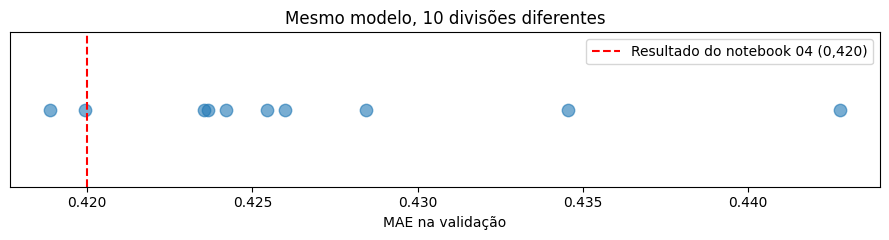

mean    0.427
std     0.007
min     0.419
max     0.443
Name: MAE árvore (max_depth=11), dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(9, 2.5))

# Cada ponto é o MAE obtido com uma divisão diferente.
ax.scatter(tabela_sementes["MAE árvore (max_depth=11)"], np.zeros(10), s=80, alpha=0.6)
ax.axvline(0.420, color="red", linestyle="--", label="Resultado do notebook 04 (0,420)")
ax.set_yticks([])   # o eixo y não significa nada aqui, então escondemos
ax.set_xlabel("MAE na validação")
ax.set_title("Mesmo modelo, 10 divisões diferentes")
ax.legend()
plt.tight_layout()
plt.show()

print(tabela_sementes["MAE árvore (max_depth=11)"].describe()[["mean", "std", "min", "max"]].round(3))

**Conclusão:** o **mesmo modelo**, com os **mesmos hiperparâmetros**, teve MAE entre **0,419 e 0,443**, dependendo só de quais casas caíram na validação. O 0,420 do notebook 04 foi um dos resultados **mais otimistas**.

Pior: a "melhor profundidade" também mudou entre **10 e 12** conforme a divisão. Se tivéssemos usado outra semente no notebook 04, teríamos escolhido outro valor.

Uma única divisão é como avaliar um aluno com **uma única prova**: ele pode ter dado sorte nas questões. Para uma avaliação justa, precisamos de **várias** provas.

## 🎓 Conceito: validação cruzada K-Fold

A **validação cruzada** (*cross-validation*) usa **todos** os dados como validação, um pedaço de cada vez:

1. Divide os dados em **K partes iguais**, chamadas **dobras** (*folds*). O mais comum é K = 5 ou 10.
2. Treina **K modelos**. Em cada rodada, uma dobra diferente fica de fora para validação, e as outras K−1 servem de treino.
3. Cada rodada produz um resultado. O resultado final é a **média** dos K resultados, acompanhada do **desvio padrão**.

Com K = 5:

```
            Dobra 1   Dobra 2   Dobra 3   Dobra 4   Dobra 5
Rodada 1:  [VALIDA ]  treino    treino    treino    treino    -> MAE₁
Rodada 2:   treino   [VALIDA ]  treino    treino    treino    -> MAE₂
Rodada 3:   treino    treino   [VALIDA ]  treino    treino    -> MAE₃
Rodada 4:   treino    treino    treino   [VALIDA ]  treino    -> MAE₄
Rodada 5:   treino    treino    treino    treino   [VALIDA ]  -> MAE₅

Resultado: média(MAE₁ ... MAE₅) ± desvio padrão
```

**Vantagens em relação a uma validação fixa:**
- **Cada casa é usada para validar exatamente uma vez.** Nenhuma casa "fácil" ou "difícil" favorece um modelo por acaso.
- **Usamos mais dados para treinar.** Em cada rodada, 80% dos dados treinam, contra 60% no notebook 04, porque não reservamos uma validação fixa.
- **Ganhamos uma medida de incerteza.** O desvio padrão diz o quanto o resultado varia.

O custo é treinar K modelos em vez de um, ou seja, levar K vezes mais tempo.

## 3. K-Fold passo a passo (à mão)

In [4]:
# KFold define COMO dividir os dados.
#   n_splits=5     -> 5 dobras
#   shuffle=True   -> embaralha as linhas antes de dividir (importante se os dados estiverem ordenados)
#   random_state=42 -> embaralhamento reproduzível
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

maes_por_dobra = []

# kfold.split(X) gera, a cada volta, duas listas de POSIÇÕES de linhas:
# as que vão para o treino e as que vão para a validação.
# enumerate(..., start=1) numera as voltas a partir de 1.
for rodada, (posicoes_treino, posicoes_val) in enumerate(kfold.split(X_train_full), start=1):
    # .iloc seleciona linhas pela posição.
    X_tr, X_val = X_train_full.iloc[posicoes_treino], X_train_full.iloc[posicoes_val]
    y_tr, y_val = y_train_full.iloc[posicoes_treino], y_train_full.iloc[posicoes_val]

    arvore = DecisionTreeRegressor(max_depth=11, random_state=42)
    arvore.fit(X_tr, y_tr)
    mae = mean_absolute_error(y_val, arvore.predict(X_val))
    maes_por_dobra.append(mae)

    print(f"Rodada {rodada}: treino com {len(X_tr)} casas, validação com {len(X_val)} casas -> MAE {mae:.3f}")

print(f"\nMédia: {np.mean(maes_por_dobra):.3f}   Desvio padrão: {np.std(maes_por_dobra):.3f}")

Rodada 1: treino com 13209 casas, validação com 3303 casas -> MAE 0.442
Rodada 2: treino com 13209 casas, validação com 3303 casas -> MAE 0.417


Rodada 3: treino com 13210 casas, validação com 3302 casas -> MAE 0.416


Rodada 4: treino com 13210 casas, validação com 3302 casas -> MAE 0.446
Rodada 5: treino com 13210 casas, validação com 3302 casas -> MAE 0.436

Média: 0.432   Desvio padrão: 0.013


**Conclusão:** cada uma das 5 rodadas treinou com ~13.200 casas e validou com ~3.300 casas **diferentes**. Os MAEs variaram de 0,416 a 0,446, e a média ficou em **0,432 ± 0,013**.

Esse número é uma estimativa **bem mais confiável** do desempenho da árvore do que o 0,420 de uma única divisão. Ele usa todas as 16.512 casas como validação, uma vez cada.

## 4. O atalho: `cross_val_score`

O scikit-learn faz todo esse laço numa única linha.

⚠️ **Um detalhe estranho:** o scikit-learn segue a regra "**maior é melhor**" para todas as métricas da validação cruzada. Como no MAE **menor** é melhor, ele devolve o MAE **negativo** (`neg_mean_absolute_error`). Basta trocar o sinal com um `-` na frente.

In [5]:
scores = cross_val_score(
    DecisionTreeRegressor(max_depth=11, random_state=42),   # o modelo (ainda não treinado)
    X_train_full, y_train_full,                             # todos os dados de treino
    cv=kfold,                                               # como dividir: nosso KFold de 5 dobras
    scoring="neg_mean_absolute_error",                      # a métrica (negativa!)
)

print("Scores devolvidos:", scores.round(3))    # negativos
maes = -scores                                  # trocando o sinal
print("MAE por dobra:    ", maes.round(3))
print(f"MAE: {maes.mean():.3f} ± {maes.std():.3f}")

Scores devolvidos: [-0.442 -0.417 -0.416 -0.446 -0.436]
MAE por dobra:     [0.442 0.417 0.416 0.446 0.436]
MAE: 0.432 ± 0.013


**Conclusão:** exatamente os mesmos números do laço manual, em uma única chamada. Como usamos o mesmo `kfold` (mesma semente), as dobras são idênticas. Daqui em diante, usamos sempre a versão pronta.

## 🎓 Conceito: como ler "média ± desvio padrão"

Um resultado como **MAE = 0,432 ± 0,013** significa:
- **0,432** é a melhor estimativa do erro do modelo em dados novos.
- **± 0,013** mostra o quanto esse número **oscila** de uma dobra para outra.

Regra prática para comparar dois modelos:
- Se a diferença entre as médias é **bem maior** que os desvios padrão, um modelo é realmente melhor.
- Se a diferença é **do tamanho** dos desvios padrão (ou menor), pode ser só **sorte da divisão**. Os modelos estão, na prática, empatados.

Vamos aplicar isso a todos os modelos da trilha.

## 5. Comparando todos os modelos com validação cruzada

In [6]:
# Reconstruímos os modelos dos notebooks anteriores.
SAO_FRANCISCO = (37.77, -122.42)
LOS_ANGELES = (34.05, -118.24)


def criar_derivados(X):
    """Proporções: quartos por cômodo e cômodos por morador."""
    X = X.copy()
    X["BedrmsPerRoom"] = X["AveBedrms"] / X["AveRooms"]
    X["RoomsPerPerson"] = X["AveRooms"] / X["AveOccup"]
    return X


def aplicar_log(X):
    """log(1 + x) nas colunas com cauda longa (usado só no modelo linear)."""
    X = X.copy()
    for coluna in ["AveRooms", "AveBedrms", "Population", "AveOccup", "RoomsPerPerson"]:
        if coluna in X.columns:
            X[coluna] = np.log1p(X[coluna])
    return X


def criar_dist_cidade(X):
    """Distância aproximada (em graus) até a cidade grande mais próxima."""
    X = X.copy()
    dist_sf = np.sqrt((X["Latitude"] - SAO_FRANCISCO[0]) ** 2 + (X["Longitude"] - SAO_FRANCISCO[1]) ** 2)
    dist_la = np.sqrt((X["Latitude"] - LOS_ANGELES[0]) ** 2 + (X["Longitude"] - LOS_ANGELES[1]) ** 2)
    X["DistCidade"] = np.minimum(dist_sf, dist_la)
    return X


modelos = {
    "Baseline (média)": DummyRegressor(),
    "Linear simples (nb 02)": LinearRegression(),
    "Linear + pré-processamento (nb 03)": Pipeline([
        ("derivados", FunctionTransformer(criar_derivados)),
        ("log", FunctionTransformer(aplicar_log)),
        ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
        ("padronizar", StandardScaler()),
        ("modelo", LinearRegression()),
    ]),
    "Árvore max_depth=11 (nb 04)": DecisionTreeRegressor(max_depth=11, random_state=42),
    "Random forest (nb 04)": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    "Random forest + atributos (nb 04)": Pipeline([
        ("derivados", FunctionTransformer(criar_derivados)),
        ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
        ("modelo", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
    ]),
}
print(f"{len(modelos)} modelos prontos para comparar.")

6 modelos prontos para comparar.


*Sobre o modelo linear do notebook 03:* aqui ele aparece **sem** a etapa que limitava as previsões ao intervalo possível (`np.clip`). Aquela etapa era aplicada depois do `.predict()`, fora do pipeline, então a validação cruzada não a enxerga. Por isso o resultado dele fica um pouco pior que no notebook 03.

Agora usamos `cross_validate`, uma versão mais completa do `cross_val_score`. Com `return_train_score=True`, ela também devolve o erro no **treino** de cada dobra, e assim conseguimos enxergar o overfitting.

In [7]:
resultados_cv = {}      # resumo (média e desvio) de cada modelo
maes_por_modelo = {}    # os 5 valores de cada modelo, para gráficos e comparações

for nome, modelo in modelos.items():
    cv = cross_validate(
        modelo, X_train_full, y_train_full,
        cv=kfold,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
    )
    # cv é um dicionário; "test_score" é o score de VALIDAÇÃO de cada dobra
    # (o scikit-learn chama de "test", mas é a dobra de validação, não o nosso teste guardado!).
    maes_val = -cv["test_score"]
    maes_treino = -cv["train_score"]
    maes_por_modelo[nome] = maes_val

    resultados_cv[nome] = {
        "MAE validação (média)": maes_val.mean(),
        "± desvio": maes_val.std(),
        "MAE treino (média)": maes_treino.mean(),
        "tempo (s)": cv["fit_time"].sum(),   # tempo total de treino nas 5 dobras
    }
    print(f"{nome:<36} MAE {maes_val.mean():.3f} ± {maes_val.std():.3f}")

tabela_cv = pd.DataFrame(resultados_cv).T
tabela_cv

Baseline (média)                     MAE 0.914 ± 0.010
Linear simples (nb 02)               MAE 0.529 ± 0.009
Linear + pré-processamento (nb 03)   MAE 0.470 ± 0.010


Árvore max_depth=11 (nb 04)          MAE 0.432 ± 0.013


Random forest (nb 04)                MAE 0.335 ± 0.005


Random forest + atributos (nb 04)    MAE 0.315 ± 0.006


,MAE validação (média),± desvio,MAE treino (média),tempo (s)
Baseline (média),0.914,0.010,0.914,0.003
Linear simples (nb 02),0.529,0.009,0.529,0.009
Linear + pré-processamento (nb 03),0.470,0.010,0.469,0.044
Árvore max_depth=11 (nb 04),0.432,0.013,0.270,0.359
Random forest (nb 04),0.335,0.005,0.124,5.605
Random forest + atributos (nb 04),0.315,0.006,0.117,8.190


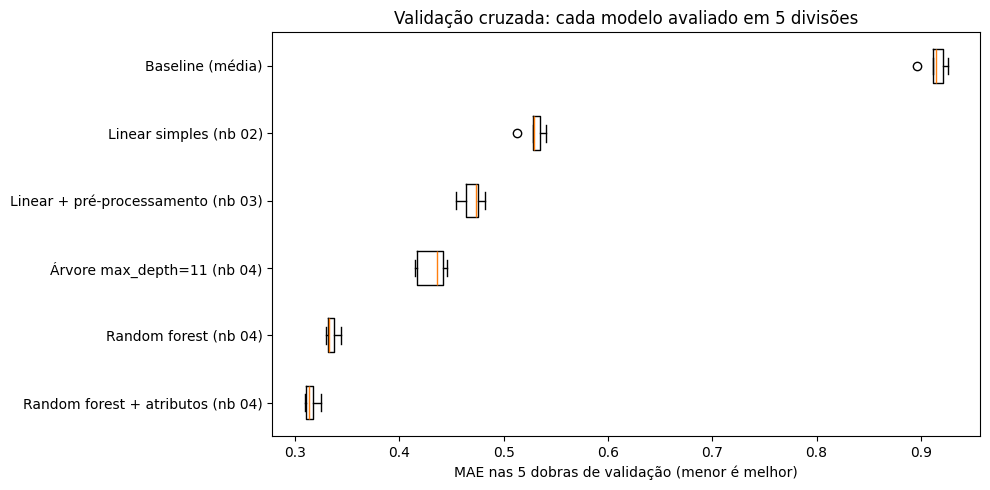

In [8]:
# Boxplot: mostra a distribuição dos 5 MAEs de cada modelo.
# A caixa vai do 25% ao 75% dos valores; a linha no meio é a mediana; os "bigodes" vão até os extremos.
nomes = list(maes_por_modelo.keys())

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([maes_por_modelo[n] for n in nomes], vert=False)
ax.set_yticks(range(1, len(nomes) + 1), nomes)
ax.set_xlabel("MAE nas 5 dobras de validação (menor é melhor)")
ax.set_title("Validação cruzada: cada modelo avaliado em 5 divisões")
ax.invert_yaxis()   # o primeiro modelo da lista aparece no topo
plt.tight_layout()
plt.show()

**Conclusão:** a validação cruzada **confirma a ordem** encontrada nos notebooks anteriores, e agora com muito mais confiança:

| Modelo | MAE (validação cruzada) | Notebook original (1 divisão) |
|---|---|---|
| Baseline | 0,914 ± 0,010 | — |
| Linear simples | 0,529 ± 0,009 | 0,533 |
| Linear + pré-processamento | 0,470 ± 0,010 | 0,465 (com o `clip`) |
| Árvore max_depth=11 | 0,432 ± 0,013 | 0,420 ← otimista |
| Random forest | 0,335 ± 0,005 | 0,335 |
| Random forest + atributos | **0,315 ± 0,006** | 0,316 |

- As caixas do boxplot **não se sobrepõem** entre famílias de modelos. Mesmo a pior dobra da random forest é muito melhor que a melhor dobra da árvore. As diferenças são reais, não sorte.
- A **árvore** foi o único caso em que a divisão única do notebook 04 enganou um pouco: 0,420 contra 0,432 na validação cruzada. E ela é o modelo **mais instável** (maior desvio, ± 0,013), como esperado de uma única árvore.
- A **random forest** é a mais estável (± 0,005): a média de 100 árvores varia menos de uma dobra para outra.
- A coluna **MAE treino** mostra o overfitting: a floresta tem erro 0,12 no treino contra 0,33 na validação. Isso continua sendo um alvo para o notebook 06.

## 6. Comparação pareada: a diferença é consistente?

Entre a **random forest** e a **random forest + atributos**, a diferença das médias é de 0,02, e os desvios são de ~0,006. Parece uma diferença real, mas dá para verificar de um jeito melhor.

🎓 **Comparação pareada:** como os dois modelos foram avaliados **nas mesmas 5 dobras**, podemos comparar **dobra a dobra**. Algumas dobras são mais difíceis que outras para **todos** os modelos. Comparando na mesma dobra, essa dificuldade se cancela, e sobra só a diferença entre os modelos.

Se um modelo vence em **todas** as dobras, a vantagem dele é consistente.

In [9]:
comparacoes = [
    ("Random forest + atributos (nb 04)", "Random forest (nb 04)"),
    ("Árvore max_depth=11 (nb 04)", "Linear + pré-processamento (nb 03)"),
]

for modelo_a, modelo_b in comparacoes:
    # Subtração elemento a elemento: dobra 1 - dobra 1, dobra 2 - dobra 2, ...
    diferencas = maes_por_modelo[modelo_a] - maes_por_modelo[modelo_b]
    vitorias = (diferencas < 0).sum()   # diferença negativa = modelo A errou menos
    print(f"{modelo_a}  vs  {modelo_b}")
    print(f"   diferença de MAE por dobra: {diferencas.round(3)}")
    print(f"   A venceu em {vitorias} de {len(diferencas)} dobras\n")

Random forest + atributos (nb 04)  vs  Random forest (nb 04)
   diferença de MAE por dobra: [-0.019 -0.016 -0.022 -0.02  -0.022]
   A venceu em 5 de 5 dobras

Árvore max_depth=11 (nb 04)  vs  Linear + pré-processamento (nb 03)
   diferença de MAE por dobra: [-0.04  -0.056 -0.039 -0.029 -0.028]
   A venceu em 5 de 5 dobras



**Conclusão:**
- **Floresta + atributos vence a floresta simples nas 5 dobras**, sempre por 0,016 a 0,022. A vantagem das colunas criadas no notebook 03 é pequena, mas **consistente**: não depende da divisão.
- **A árvore vence o linear do notebook 03 nas 5 dobras**, por 0,028 a 0,056. Em MAE, a vantagem dela também é real (lembrando que no notebook 04 vimos que o RMSE conta outra história).

Essa comparação pareada é mais convincente do que olhar só as médias. O desvio padrão de cada modelo inclui a dificuldade de cada dobra, enquanto a diferença dobra a dobra elimina esse efeito.

## 7. Curva de complexidade com validação cruzada

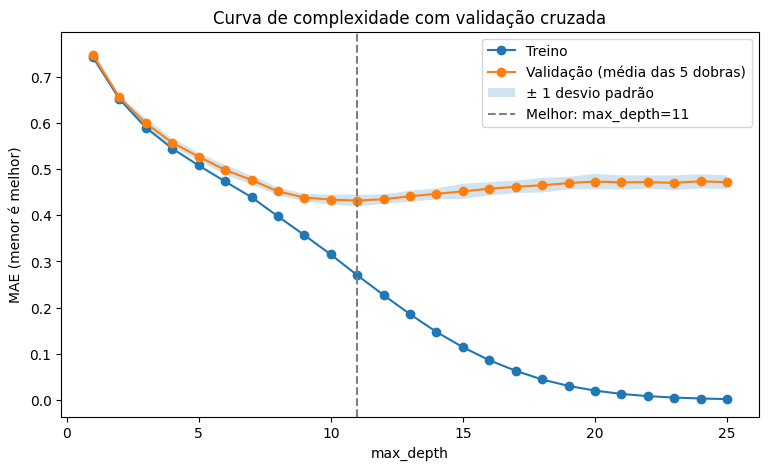

,MAE validação,± desvio
8,0.451,0.008
9,0.438,0.008
10,0.434,0.011
11,0.432,0.013
12,0.434,0.010
13,0.441,0.012
14,0.446,0.012


In [10]:
# validation_curve faz a validação cruzada para CADA valor de um hiperparâmetro.
# Aqui: 25 profundidades × 5 dobras = 125 árvores treinadas.
profundidades = np.arange(1, 26)   # np.arange(1, 26) = [1, 2, ..., 25]

scores_treino, scores_val = validation_curve(
    DecisionTreeRegressor(random_state=42),
    X_train_full, y_train_full,
    param_name="max_depth",          # nome do hiperparâmetro que vai variar
    param_range=profundidades,       # valores a testar
    cv=kfold,
    scoring="neg_mean_absolute_error",
)

# O resultado é uma tabela: uma linha por profundidade, uma coluna por dobra.
# .mean(axis=1) faz a média de cada LINHA (ou seja, das 5 dobras de cada profundidade).
mae_treino = -scores_treino.mean(axis=1)
mae_val = -scores_val.mean(axis=1)
desvio_val = scores_val.std(axis=1)

melhor = profundidades[np.argmin(mae_val)]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(profundidades, mae_treino, marker="o", label="Treino")
ax.plot(profundidades, mae_val, marker="o", label="Validação (média das 5 dobras)")
# fill_between pinta uma faixa: aqui, de (média - desvio) até (média + desvio).
ax.fill_between(profundidades, mae_val - desvio_val, mae_val + desvio_val, alpha=0.2,
                label="± 1 desvio padrão")
ax.axvline(melhor, color="gray", linestyle="--", label=f"Melhor: max_depth={melhor}")
ax.set_xlabel("max_depth")
ax.set_ylabel("MAE (menor é melhor)")
ax.set_title("Curva de complexidade com validação cruzada")
ax.legend()
plt.show()

# Os valores perto do melhor:
pd.DataFrame({"MAE validação": mae_val, "± desvio": desvio_val}, index=profundidades).loc[8:14].round(3)

**Conclusão:** a validação cruzada **confirma** `max_depth=11` como a melhor profundidade (MAE 0,432). Mas repare na tabela: as profundidades 10, 11 e 12 têm MAE de 0,434, 0,432 e 0,434. A diferença entre elas (0,002) é **muito menor** que o desvio padrão (~0,013). Na prática, **estão empatadas**.

A faixa sombreada mostra isso visualmente: perto do mínimo, as faixas das profundidades vizinhas se sobrepõem quase totalmente.

**Lição:** quando vários valores empatam, uma boa prática é escolher o **mais simples** (aqui, a menor profundidade), porque modelos mais simples costumam generalizar melhor e são mais fáceis de entender. E não vale a pena gastar tempo "otimizando" diferenças menores que o ruído.

## 8. Validação cruzada e vazamento de dados

No notebook 03, aprendemos que tudo que **aprende** com os dados (como a média do `StandardScaler`) deve aprender **só com o treino**. Na validação cruzada, isso vale **para cada dobra**.

É por isso que passamos o **pipeline inteiro** para o `cross_validate`, e não dados já padronizados:

```python
# ❌ ERRADO: o padronizador aprende com TODAS as linhas, inclusive as que
#            vão servir de validação em cada dobra -> vazamento
X_padronizado = StandardScaler().fit_transform(X_train_full)
cross_val_score(LinearRegression(), X_padronizado, y_train_full, cv=kfold)

# ✅ CERTO: em cada dobra, o pipeline faz o fit do padronizador só com as 4 dobras de treino
pipeline = Pipeline([("padronizar", StandardScaler()), ("modelo", LinearRegression())])
cross_val_score(pipeline, X_train_full, y_train_full, cv=kfold)
```

O pipeline é o que garante que **cada rodada** da validação cruzada simule de verdade "dados nunca vistos". Ele e a validação cruzada foram feitos para trabalhar juntos.

## 9. Quantas dobras usar?

| K | Treino em cada rodada | Vantagem | Desvantagem |
|---|---|---|---|
| **5** | 80% dos dados | Rápido; o padrão mais comum | Estimativa um pouco mais "ruidosa" |
| **10** | 90% dos dados | Cada modelo treina com mais dados | 2× mais lento que K=5 |
| **N** (uma linha por dobra, *leave-one-out*) | Todos menos 1 | Usa o máximo de dados | Treina N modelos: inviável com 16 mil linhas |

Para este dataset, **K = 5** é um bom equilíbrio: na seção 5, a random forest levou só alguns segundos por modelo. Em datasets **pequenos** (poucas centenas de linhas), vale usar K = 10, porque cada linha de treino faz mais diferença.

## 10. E o conjunto de teste?

Repare que **não usamos o teste** neste notebook, e nem precisamos.

A validação cruzada **confirmou a escolha** do notebook 04: o melhor modelo continua sendo a **random forest + atributos**, com MAE estimado de **0,315 ± 0,006**. Como o modelo escolhido é o mesmo, a avaliação no teste do notebook 04 continua valendo: **MAE 0,306**.

Repare como os dois números são próximos: a validação cruzada estimou 0,315, e o teste deu 0,306. A estimativa da validação cruzada foi **confiável**.

O teste só deve ser usado de novo quando tivermos um **modelo final diferente**, o que vai acontecer no notebook 07, depois de ajustarmos os hiperparâmetros.

## 11. Resumo e próximos passos

**Conceitos que você aprendeu**
- Uma **única divisão** treino/validação pode enganar: o mesmo modelo variou de 0,419 a 0,443.
- **Validação cruzada K-Fold**: K rodadas, cada dobra validando uma vez. O resultado é **média ± desvio padrão**.
- `cross_val_score`, `cross_validate` e o **sinal negativo** das métricas de erro no scikit-learn.
- **Ler incerteza**: diferenças menores que o desvio padrão podem ser só sorte.
- **Comparação pareada**: comparar modelos dobra a dobra.
- **Curva de complexidade com validação cruzada** e a preferência pelo modelo mais simples em caso de empate.
- **Pipeline + validação cruzada** contra o vazamento de dados.

**Python novo:** `min(..., key=função)`, funções definidas dentro de um laço, `enumerate(..., start=1)`, `np.arange`, `.mean(axis=1)` e `fill_between`.

**O que a validação cruzada mostrou**
- ✅ A ordem dos modelos é **real**: baseline < linear < linear + pré-processamento < árvore < floresta < floresta + atributos.
- ✅ As colunas do notebook 03 ajudam a floresta de forma **consistente** (venceram nas 5 dobras).
- ⚠️ O resultado da árvore no notebook 04 (0,420) foi **otimista**. O valor mais confiável é 0,432.
- ⚠️ A floresta ainda tem um grande **overfitting** (0,12 no treino contra 0,32 na validação).

**Próximo notebook (06):** ajuste de hiperparâmetros. Até aqui, só ajustamos o `max_depth` da árvore, testando um hiperparâmetro de cada vez. A floresta tem vários hiperparâmetros (`max_depth`, `min_samples_leaf`, `max_features`...) que interagem entre si. Vamos usar `GridSearchCV` e `RandomizedSearchCV`, que **combinam a busca de hiperparâmetros com a validação cruzada**, para tentar reduzir o overfitting e o erro da floresta.